In [6]:
#MLR(multiple liear regration)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import (StandardScaler,OneHotEncoder)

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)


In [7]:
df=pd.read_csv("./Housing.csv")
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [8]:
df.shape

(545, 13)

In [9]:
df.tail()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [11]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [12]:
df.isnull()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,False,False,False,False,False,False,False,False,False,False,False,False,False
541,False,False,False,False,False,False,False,False,False,False,False,False,False
542,False,False,False,False,False,False,False,False,False,False,False,False,False
543,False,False,False,False,False,False,False,False,False,False,False,False,False


In [13]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [14]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [15]:
df.describe(include='object')

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


check missing values and duplicate  and outliear

In [16]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [17]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
540,False
541,False
542,False
543,False


In [18]:
df.duplicated().sum()

np.int64(0)

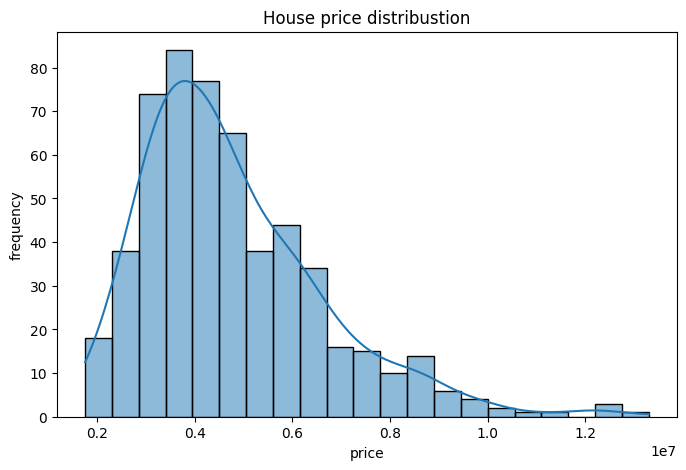

In [19]:
plt.figure(figsize=(8,5))
sns.histplot(df["price"],kde=True)
plt.title("House price distribustion")
plt.xlabel("price")
plt.ylabel("frequency")
plt.show()


In [20]:
df['price'].value_counts()

,count
price,
4200000,17
3500000,17
4900000,12
5250000,9
5600000,9
...,...
2135000,1
1960000,1
1855000,1


Area VS price

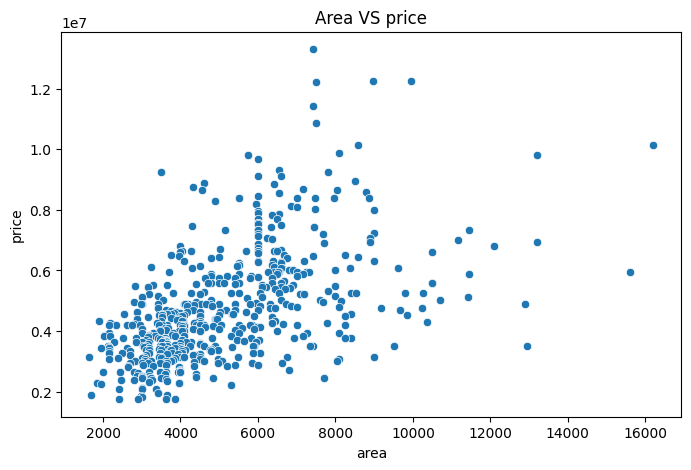

In [21]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="area",y="price",data=df)
plt.title("Area VS price")
plt.xlabel("area")
plt.ylabel("price")
plt.show()


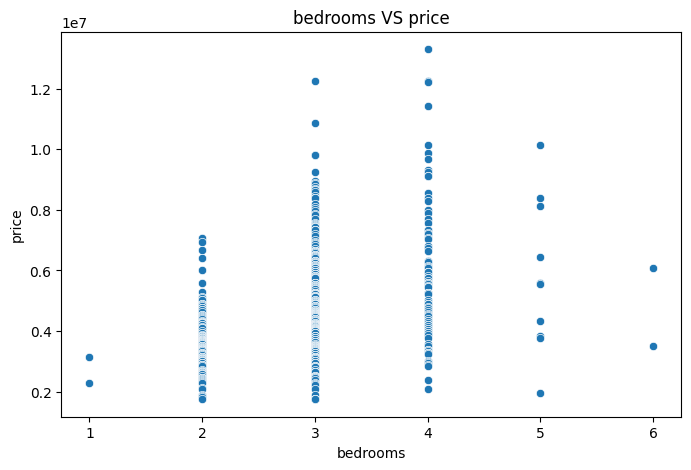

In [22]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="bedrooms",y="price",data=df)
plt.title("bedrooms VS price")
plt.xlabel("bedrooms")
plt.ylabel("price")
plt.show()

In [23]:
df['bedrooms'].value_counts()

,count
bedrooms,
3,300
2,136
4,95
5,10
6,2
1,2


**correlation heatmap**

In [24]:
X = df.drop('price',axis=1)
y = df['price']

In [25]:
X

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...
540,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [26]:
y

,price
0,13300000
1,12250000
2,12250000
3,12215000
4,11410000
...,...
540,1820000
541,1767150
542,1750000
543,1750000


In [27]:
X.shape

(545, 12)

In [28]:
y.shape

(545,)

**train_test_split**

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)
X_train.shape

(436, 12)

In [30]:
X_test.shape

(109, 12)

**identifying the numerical datasets**

In [31]:
numeric_features = X.select_dtypes(include=["int64","float64"]).columns.tolist()
numeric_features

['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

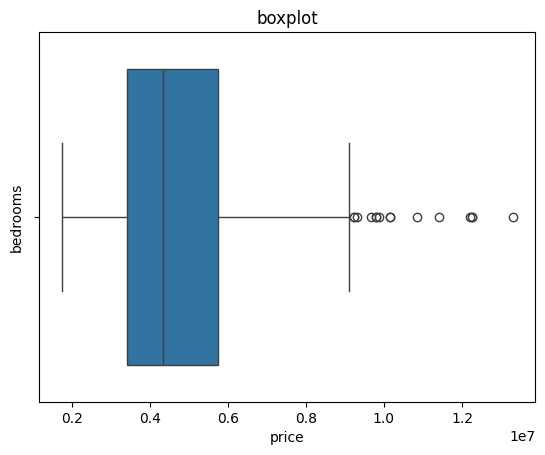

In [32]:
sns.boxplot(x="price",data=df)
plt.xlabel("price")
plt.ylabel("bedrooms")
plt.title("boxplot")
plt.show()

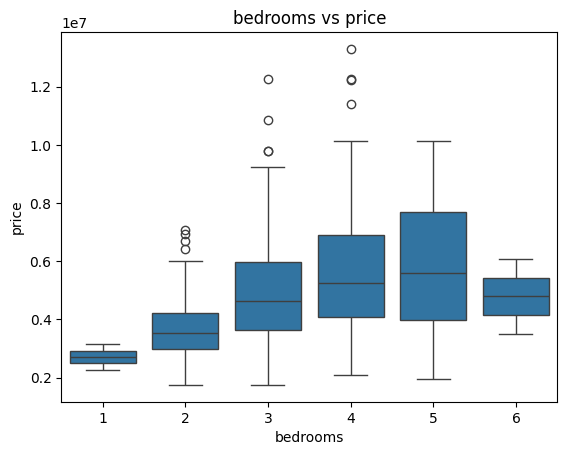

In [33]:
sns.boxplot(x="bedrooms",y='price',data=df)
plt.xlabel("bedrooms")
plt.ylabel("price")
plt.title("bedrooms vs price")
plt.show()

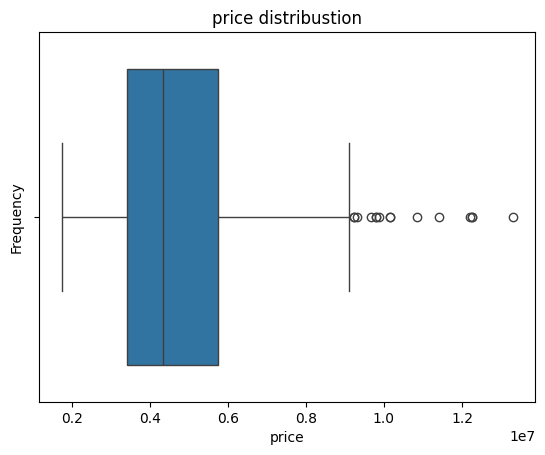

In [34]:
sns.boxplot(x="price",data=df)
plt.xlabel("price")
plt.ylabel("Frequency")
plt.title("price distribustion")
plt.show()

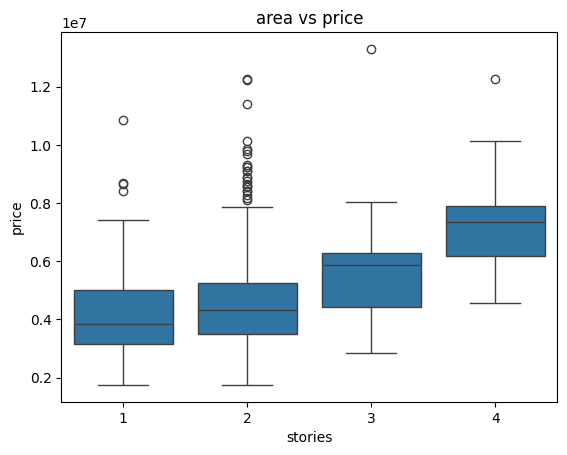

In [35]:
sns.boxplot(x="stories",y="price",data=df)
plt.xlabel("stories")
plt.ylabel("price")
plt.title("area vs price")
plt.show()

c**orrelation headtmap** **bold text**

Text(0.5, 1.0, 'Correlation Heatmap')

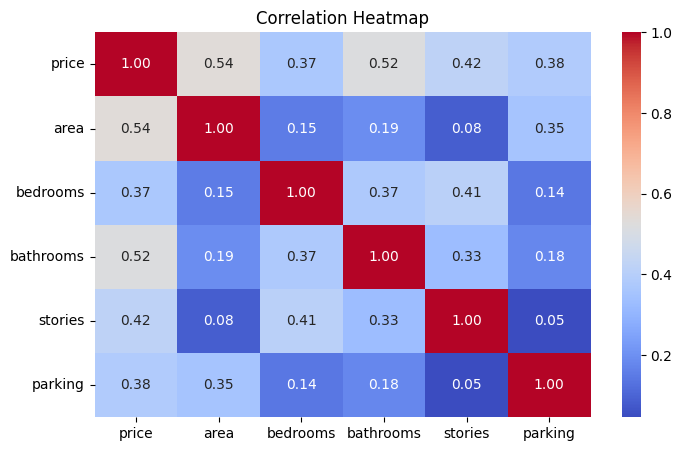

In [36]:
plt.figure(figsize=(8,5))
sns.heatmap(
    df.select_dtypes(include=[np.number]).corr(),
    cmap="coolwarm",
    fmt=".2f",
    annot=True)
plt.title("Correlation Heatmap")

In [37]:
x= df.drop('price',axis=1)
y=df['price']

In [38]:
x

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...
540,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [39]:
y

,price
0,13300000
1,12250000
2,12250000
3,12215000
4,11410000
...,...
540,1820000
541,1767150
542,1750000
543,1750000


**Identifying the numerical datasets**

*   List item
*   List item
[**standrization**]



In [40]:
numeric_features = X.select_dtypes(include=["int64","float64"]).columns.tolist()
numeric_features

['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

**Categoricalfeatures**

In [41]:
categorical_features =x.select_dtypes(include=["object"]).columns.tolist()
categorical_features

['mainroad',
 'guestroom',
 'basement',
 'hotwaterheating',
 'airconditioning',
 'prefarea',
 'furnishingstatus']

In [42]:
X[["area","bedrooms"]]

,area,bedrooms
0,7420,4
1,8960,4
2,9960,3
3,7500,4
4,7420,4
...,...,...
540,3000,2
541,2400,3
542,3620,2
543,2910,3


In [43]:
X[["area","bathrooms"]]

,area,bathrooms
0,7420,2
1,8960,4
2,9960,2
3,7500,2
4,7420,1
...,...,...
540,3000,1
541,2400,1
542,3620,1
543,2910,1


In [44]:
X[["area","bedrooms","bathrooms"]]

,area,bedrooms,bathrooms
0,7420,4,2
1,8960,4,4
2,9960,3,2
3,7500,4,2
4,7420,4,1
...,...,...,...
540,3000,2,1
541,2400,3,1
542,3620,2,1
543,2910,3,1


In [45]:
scaler = StandardScaler()
scaled_data =scaler.fit_transform(X_train[numeric_features])
scaled_data

array([[ 0.38416819,  0.05527092,  1.53917323,  2.58764353,  0.36795665],
       [ 0.9291807 ,  0.05527092,  1.53917323, -0.91249891,  2.70998729],
       [-0.60775457, -1.28351359, -0.5579503 , -0.91249891,  1.53897197],
       ...,
       [-0.29709744,  0.05527092,  1.53917323,  1.42092939,  0.36795665],
       [-0.5060189 , -1.28351359, -0.5579503 , -0.91249891, -0.80305867],
       [ 0.15707965,  0.05527092,  1.53917323,  2.58764353,  0.36795665]],
      shape=(436, 5))

In [46]:
X_train[categorical_features]

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
46,yes,no,no,no,yes,no,furnished
93,yes,no,yes,no,yes,no,semi-furnished
335,yes,no,yes,no,yes,no,furnished
412,yes,no,yes,no,no,yes,unfurnished
471,yes,no,no,no,no,no,unfurnished
...,...,...,...,...,...,...,...
71,yes,no,no,no,yes,no,unfurnished
106,yes,no,yes,no,yes,yes,semi-furnished
270,yes,no,no,yes,no,no,furnished
435,yes,no,no,no,no,no,unfurnished


In [47]:
encoder =OneHotEncoder(handle_unknown="ignore",drop="first")
encoder_data =encoder.fit_transform(X_train[categorical_features])
encoder_data.toarray()


array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 1., ..., 0., 1., 0.],
       [1., 0., 1., ..., 0., 0., 0.],
       ...,
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 1.],
       [1., 1., 0., ..., 0., 1., 0.]], shape=(436, 8))

**Instead of transforming numerical and categorical columns separetly everytime, we can automate the process using ColumnTransformer**

In [48]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric",StandardScaler(),numeric_features),
        ("categorical",OneHotEncoder(handle_unknown="ignore",drop="first"),categorical_features)
    ]

)
preprocessor

ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                 ['area', 'bedrooms', 'bathrooms', 'stories',
                                  'parking']),
                                ('categorical',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['mainroad', 'guestroom', 'basement',
                                  'hotwaterheating', 'airconditioning',
                                  'prefarea', 'furnishingstatus'])])

In [49]:
model= Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("regressor",LinearRegression())
    ]
)
model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['area', 'bedrooms',
                                                   'bathrooms', 'stories',
                                                   'parking']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['mainroad', 'guestroom',
                                                   'basement',
                                                   'hotwaterheating',
                                                   'airconditioning',
                                                   'prefarea',
                                                   'furnishingstatus'])])),
                ('regressor', LinearRegression())])

In [50]:
model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['area', 'bedrooms',
                                                   'bathrooms', 'stories',
                                                   'parking']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['mainroad', 'guestroom',
                                                   'basement',
                                                   'hotwaterheating',
                                                   'airconditioning',
                                                   'prefarea',
                                                   'furnishingstatus'])])),
                ('regressor', LinearRegression())])

In [51]:
y_pred=model.predict(X_test)
y_pred[:10]


array([5164653.90033967, 7224722.29802166, 3109863.24240338,
       4612075.3272256 , 3294646.25725956, 3532275.09556558,
       5611774.56836474, 6368145.98732718, 2722856.95689986,
       2629405.61585783])

In [52]:
y_pred=model.predict(X_test)
y_pred[:12]

array([5164653.90033967, 7224722.29802166, 3109863.24240338,
       4612075.3272256 , 3294646.25725956, 3532275.09556558,
       5611774.56836474, 6368145.98732718, 2722856.95689986,
       2629405.61585783, 9617039.50315579, 2798087.30447888])

In [53]:
comparison = pd.DataFrame({"Actual":y_test,"predicted":y_pred})
comparison.head()

,Actual,predicted
316,4060000,5.164654e+06
77,6650000,7.224722e+06
360,3710000,3.109863e+06
90,6440000,4.612075e+06
493,2800000,3.294646e+06


In [54]:
mae = mean_absolute_error(y_test,y_pred)
mae

970043.403920164

In [55]:
mse= mean_squared_error(y_test,y_pred)
mse

1754318687330.6667

In [56]:
r2=r2_score(y_test,y_pred)
r2

0.6529242642153178

In [57]:
rmse=np.sqrt(mse)
rmse

np.float64(1324506.9600914398)

In [58]:
evaluation=pd.DataFrame(
    {
    "model":["Linear Regression"],
    "MAE":[mae],
    "MSE":[mse],
    "RMSE":[rmse],
    "r2 score":[r2]
    }
)
evaluation

,model,MAE,MSE,RMSE,r2 score
0,Linear Regression,970043.40392,1.754319e+12,1.324507e+06,0.652924


In [60]:
new_house=pd.DataFrame([{
    "area":6800,
    "bedrooms":5,
    "bathrooms":3,
    "mainroad":"yes",
    "guestroom":"no",
    "stories":2,
    "basement":"no",
    "hotwaterheating":"yes",
    "airconditioning":"yes",
    "parking":"2",
    "prefarea":"yes",
    "furnishingstatus":"furnished"
}])
predicted_price =model.predict(new_house)
predicted_price

array([9270372.24566057])

In [66]:
#EXtract trained regression model
regressor = model.named_steps["regressor"]

# Get intercept(b0)
b0= regressor.intercept_
# Get coefficients = (b1,b2,b3)
coefficients =regressor.coef_
# Get transformed feature names
feature_names=(
    model.named_steps["preprocessor"].get_feature_names_out()

)
print("Intercept(b0):",b0)
print("\nRegression coefficients:")
for i, coefficient in enumerate(coefficients):
  print(f"b{i+1} ({feature_names[i]})={coefficients}")

Intercept(b0): 3969403.5565888807

Regression coefficients:
b1 (numeric__area)=[ 519552.41633999   57349.55941862  521879.02774805  349251.43890557
  192005.95366749  367919.94767957  231610.03717565  390251.17618109
  684649.88533879  791426.73584319  629890.56531336 -126881.81758511
 -413645.06222822]
b2 (numeric__bedrooms)=[ 519552.41633999   57349.55941862  521879.02774805  349251.43890557
  192005.95366749  367919.94767957  231610.03717565  390251.17618109
  684649.88533879  791426.73584319  629890.56531336 -126881.81758511
 -413645.06222822]
b3 (numeric__bathrooms)=[ 519552.41633999   57349.55941862  521879.02774805  349251.43890557
  192005.95366749  367919.94767957  231610.03717565  390251.17618109
  684649.88533879  791426.73584319  629890.56531336 -126881.81758511
 -413645.06222822]
b4 (numeric__stories)=[ 519552.41633999   57349.55941862  521879.02774805  349251.43890557
  192005.95366749  367919.94767957  231610.03717565  390251.17618109
  684649.88533879  791426.73584319  

In [68]:
coefficient_df=pd.DataFrame({
    "cofficient": ["b0"] +[
        f" b{i+1}" for i in range(len(coefficients))

    ],
"Feature": ["intercept"] + list(feature_names),
"value": ["Intercept"] + list(feature_names),
    "value":[b0]+ list(coefficients)
})
coefficient_df

,cofficient,Feature,value
0,b0,intercept,3.969404e+06
1,b1,numeric__area,5.195524e+05
2,b2,numeric__bedrooms,5.734956e+04
3,b3,numeric__bathrooms,5.218790e+05
4,b4,numeric__stories,3.492514e+05
5,b5,numeric__parking,1.920060e+05
6,b6,categorical__mainroad_yes,3.679199e+05
7,b7,categorical__guestroom_yes,2.316100e+05
8,b8,categorical__basement_yes,3.902512e+05
9,b9,categorical__hotwaterheating_yes,6.846499e+05


In [81]:

from sklearn.linear_model import SGDRegressor
from sklearn.compose import TransformedTargetRegressor

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", TransformedTargetRegressor(
            regressor=SGDRegressor(
                loss="squared_error",
                penalty=None,
                max_iter=5000,
                learning_rate="constant",
                eta0=0.01,
                tol=1e-6,
                random_state=42
            ),
            transformer=StandardScaler()
        ))
    ]
)

model


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['area', 'bedrooms',
                                                   'bathrooms', 'stories',
                                                   'parking']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['mainroad', 'guestroom',
                                                   'basement',
                                                   'hotwaterheating',
                                                   'airconditioning',
                                                   'prefarea',
                                                   'furnishingstatus'])])),
                ('regressor',
                 TransformedTargetRegressor(regressor=SGDRegressor(learning_rate='constant',
                                                                   max_iter=5000,
                                                                   penalty=None,
                                                                   random_state=42,
                                                                   tol=1e-06),
                                            transformer=StandardScaler()))])

In [83]:
model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['area', 'bedrooms',
                                                   'bathrooms', 'stories',
                                                   'parking']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['mainroad', 'guestroom',
                                                   'basement',
                                                   'hotwaterheating',
                                                   'airconditioning',
                                                   'prefarea',
                                                   'furnishingstatus'])])),
                ('regressor',
                 TransformedTargetRegressor(regressor=SGDRegressor(learning_rate='constant',
                                                                   max_iter=5000,
                                                                   penalty=None,
                                                                   random_state=42,
                                                                   tol=1e-06),
                                            transformer=StandardScaler()))])

In [86]:
y_pred = model.predict(X_test)
comparision = pd.DataFrame({"Actual": y_test,"predicted": y_pred
    })
comparison.head()

,Actual,predicted
316,4060000,5.164654e+06
77,6650000,7.224722e+06
360,3710000,3.109863e+06
90,6440000,4.612075e+06
493,2800000,3.294646e+06


In [88]:

# Extract trained SGD model
sgd_model = model.named_steps["regressor"].regressor_

# Target scaler
y_scaler = model.named_steps["regressor"].transformer_

# Convert coefficients back to original price scale
coefficients = sgd_model.coef_ * y_scaler.scale_[0]

b0 = (
    y_scaler.mean_[0]
    + y_scaler.scale_[0] * sgd_model.intercept_[0]
)

# Feature names
feature_names = (
    model.named_steps["preprocessor"].get_feature_names_out()
)

print("Intercept (b0):", b0)

for i, value in enumerate(coefficients):
    print(f"b{i+1} ({feature_names[i]}) = {value:.2f}")


Intercept (b0): 3987853.973249928
b1 (numeric__area) = 430020.13
b2 (numeric__bedrooms) = 120766.15
b3 (numeric__bathrooms) = 475668.05
b4 (numeric__stories) = 324039.41
b5 (numeric__parking) = 281859.21
b6 (categorical__mainroad_yes) = 317264.56
b7 (categorical__guestroom_yes) = 204687.26
b8 (categorical__basement_yes) = 389624.34
b9 (categorical__hotwaterheating_yes) = 611048.58
b10 (categorical__airconditioning_yes) = 754595.74
b11 (categorical__prefarea_yes) = 605991.97
b12 (categorical__furnishingstatus_semi-furnished) = -174502.71
b13 (categorical__furnishingstatus_unfurnished) = -456930.44


In [100]:
new_house = pd.DataFrame([{
    "area": 8000,
    "bedrooms": 2,
    "bathrooms": 2,
    "stories":2,
    "mainroad":'yes',
    "guestroom": "no",
    "basement": "no",
    "hotwaterheating":"no",
    "airconditioning": "yes",
    "parking": 1,
    "prefarea":"yes",
    "furnishingstatus":"furnished"
    }])
predicted_price = model.predict(new_house)
print("Predicted House price:",predicted_price[0])

Predicted House price: 6984735.141547981
